In [ ]:
#| default_exp player

# A player

> Play, pause at the word, seek, skip and change speed, on Kokoro and Sonic.

Notebooks 100 and 101 found the pieces: Kokoro renders a sentence about 8x faster than real time and says where every
word is, and Sonic speeds up 1x audio better than Kokoro can itself. This notebook puts them together into the
controls audio-reader gives Alex.

The design in one paragraph. The text is split into sentences. A background thread renders the next few at 1x, so
there is always audio ready. The sound card asks for audio in small blocks through `pull(n)`, which takes 1x audio from
the current sentence, passes it through a Sonic stream, and returns sped-up audio. Everything the player knows (where
it is, where the words are, where to pause) is in 1x samples; only Sonic knows the speed. That's why changing speed is
instant, and why `pull` works without speakers too, which is how we test it.

Some differences from audio-reader, all because we hold the audio rather than asking a voice to speak:

- **Sentences, not 320-character chunks.** audio-reader packs sentences into chunks because Alex can only stop
  cleanly between utterances. We can stop anywhere, so the unit can be as small as Kokoro likes, and the first sound
  comes sooner.
- **Seek to a word, not a chunk.** We know where every word starts.
- **Speed changes without a rewind.** audio-reader restarts the chunk at the new rate.

In [ ]:
#| export
import ctypes
import re
import subprocess
import threading
from collections import namedtuple
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import sounddevice as sd
import spacy

import text_to_speech
from text_to_speech.pretrained import SR, say, word_spans

/Users/henrydashwood/text-to-speech/.venv/lib/python3.13/site-packages/torch/nn/modules/rnn.py:1011: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.2 and num_layers=1
  super().__init__("LSTM", *args, **kwargs)
/Users/henrydashwood/text-to-speech/.venv/lib/python3.13/site-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
/Users/henrydashwood/text-to-speech/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

In [ ]:
import time
from html import escape

import ipywidgets as widgets
import matplotlib.pyplot as plt
from huggingface_hub import list_repo_files
from IPython.display import Audio, display

## Sentences

spaCy, which Kokoro's frontend already uses, finds the sentence boundaries. We split into paragraphs first so a
sentence never runs across a paragraph break, and keep character offsets into the original text, which is what
audio-reader saves as a reading position.

In [ ]:
#| export
nlp = spacy.load("en_core_web_sm", exclude=["ner", "lemmatizer"])


def sentence_spans(text):
    "(start, end) character offsets of every sentence in `text`. Paragraphs are separated by blank lines."
    spans = []
    for para in re.finditer(r"[^\n]+(?:\n[^\n]+)*", text):
        spans += [(para.start() + s.start_char, para.start() + s.end_char) for s in nlp(para.group()).sents]
    return [(a, b) for a, b in spans if text[a:b].strip()]

In [ ]:
article = """Talking machines are older than computers. In 1939 Homer Dudley's Voder, played like an organ by a trained
operator, spoke at the New York World's Fair. It took a year of practice to make it say anything at all.

Dr. Dennis Klatt's work at MIT in the 1970s and 1980s gave the world rule-based voices that ran on a chip. Stephen
Hawking used one for decades, and kept it after better ones existed, because it had become his voice.

Neural voices arrived in 2016. They sound far more human, but they are large, and for a long time they could not run
on a phone at all. Making one small enough, and controllable enough, is the point of this project."""

for a, b in sentence_spans(article):
    print(f"{a:>4}-{b:<4} {article[a:b]!r}")

   0-42   'Talking machines are older than computers.'
  43-152  "In 1939 Homer Dudley's Voder, played like an organ by a trained\noperator, spoke at the New York World's Fair."
 153-211  'It took a year of practice to make it say anything at all.'
 213-319  "Dr. Dennis Klatt's work at MIT in the 1970s and 1980s gave the world rule-based voices that ran on a chip."
 320-429  'Stephen\nHawking used one for decades, and kept it after better ones existed, because it had become his voice.'
 431-461  'Neural voices arrived in 2016.'
 462-566  'They sound far more human, but they are large, and for a long time they could not run\non a phone at all.'
 567-646  'Making one small enough, and controllable enough, is the point of this project.'


## Rendering a sentence

`render_sentence` asks Kokoro for one sentence and keeps every word's place in the article and in the audio. Kokoro
pads each render with silence before and after (audio-reader's prototype measured about 0.3 s and 0.7 s), which
would add a second of dead air between sentences. We know where the first and last words are, so we cut there,
keeping a margin because the timestamps are approximate. Punctuation tokens and ones Kokoro gave no time (like `$`)
aren't words to highlight, so they're dropped. And a line break inside a paragraph becomes a space, or Kokoro's
frontend treats the words either side as one.

In [ ]:
#| export
Word = namedtuple("Word", "char_start char_end sample_start sample_end")


@dataclass
class Sentence:
    audio: np.ndarray  # float32 at 1x, trimmed to the speech
    words: list  # A Word for each spoken word, positions in the text and in `audio`


def render_sentence(text, start, end, voice="af_heart", margin=(0.1, 0.25)):
    "Kokoro's audio for `text[start:end]`, with every word's position in `text` and in the audio."
    sentence = text[start:end].replace("\n", " ")  # Same length, and Kokoro won't join words across a line break
    r = say(sentence, voice=voice)
    spans = word_spans(sentence, r.tokens).dropna()
    spans = spans[spans.text.str.contains(r"\w")]
    first = max(0, int((spans.start.min() - margin[0]) * SR))
    last = int((spans.end.max() + margin[1]) * SR)
    words = [
        Word(start + w.char_start, start + w.char_end, int(w.start * SR) - first, int(w.end * SR) - first)
        for w in spans.itertuples()
    ]
    return Sentence(r.audio.numpy()[first:last].astype(np.float32), words)

In [ ]:
a, b = sentence_spans(article)[0]
s = render_sentence(article, a, b)
print(f"{len(s.audio) / SR:.2f}s, {len(s.words)} words:", [article[w.char_start : w.char_end] for w in s.words])
Audio(s.audio, rate=SR)

2.85s, 6 words: ['Talking', 'machines', 'are', 'older', 'than', 'computers']


## Sonic as a stream

Notebook 101 used Sonic's one-shot function. The player needs its streaming interface instead: write 1x audio in,
read sped-up audio out, and change the speed whenever you like. We compile the vendored C the first time it's needed.

In [ ]:
#| export
SONIC = Path(text_to_speech.__file__).parents[1] / "vendor" / "sonic"


def load_sonic():
    "Compile `vendor/sonic/sonic.c` into a shared library if it isn't there yet, and load it."
    lib = SONIC / "libsonic.dylib"
    if not lib.exists():
        subprocess.run(["cc", "-O2", "-shared", "-fPIC", SONIC / "sonic.c", "-o", lib], check=True)
    lib = ctypes.CDLL(str(lib))
    p, i, f = ctypes.c_void_p, ctypes.c_int, ctypes.c_float
    floats = ctypes.POINTER(ctypes.c_float)
    lib.sonicCreateStream.argtypes, lib.sonicCreateStream.restype = [i, i], p
    lib.sonicDestroyStream.argtypes = [p]
    lib.sonicSetSpeed.argtypes = [p, f]
    lib.sonicWriteFloatToStream.argtypes = [p, floats, i]
    lib.sonicReadFloatFromStream.argtypes = [p, floats, i]
    lib.sonicFlushStream.argtypes = [p]
    return lib


libsonic = load_sonic()


class Sonic:
    "Sonic's streaming interface: write 1x audio in, read sped-up audio out, change the speed at any time."

    def __init__(self, speed=1.0):
        self.lib = libsonic  # Held here so `__del__` still has it while Python shuts down
        self.stream = self.lib.sonicCreateStream(SR, 1)
        self.set_speed(speed)

    def set_speed(self, speed):
        self.lib.sonicSetSpeed(self.stream, speed)

    def write(self, x):
        self.lib.sonicWriteFloatToStream(self.stream, x.ctypes.data_as(ctypes.POINTER(ctypes.c_float)), len(x))

    def read(self, out):
        "Fill as much of `out` as Sonic has ready. Returns how many samples that was."
        return self.lib.sonicReadFloatFromStream(
            self.stream, out.ctypes.data_as(ctypes.POINTER(ctypes.c_float)), len(out)
        )

    def flush(self):
        "Process whatever has been written, without waiting for more."
        self.lib.sonicFlushStream(self.stream)

    def __del__(self):
        self.lib.sonicDestroyStream(self.stream)

A second of audio in at 2x should be half a second out:

In [ ]:
sonic, out = Sonic(2), np.zeros(SR, np.float32)
sonic.write(s.audio[:SR])
sonic.flush()
print(sonic.read(out) / SR, "seconds")

0.4965833333333333 seconds


## The player

The state is small: which sentence, how far into it (in 1x samples), the speed, and one of four modes. *Playing*;
*pausing*, still playing up to the end of the current word; *draining*, letting Sonic empty out what it holds; and
*paused*.

`pull(n)` is the whole audio path. It reads what Sonic has ready, and when that runs out it feeds Sonic the next block
of 1x audio with `_feed`, which is also where words are announced, pauses land and sentences advance. If the next
sentence isn't rendered yet it returns silence rather than waiting, because the sound card won't wait either.

The position is in 1x seconds, like audio-reader's media time, so it doesn't move when the speed does. Sentences not
rendered yet count at an estimated 15 characters a second, which is what notebook 100 measured.

In [ ]:
#| export
CHARS_PER_SECOND = 15  # Kokoro at 1x, measured in notebook 100
BLOCK = 1024  # 1x samples fed to Sonic at a time


class Player:
    "Reads `text` aloud. Like audio-reader's ArticlePlayer: play, pause at a word, seek, skip and speed."

    def __init__(self, text, speed=1.0, voice="af_heart", on_word=None, lookahead=2):
        self.text, self.voice, self.on_word, self.lookahead = text, voice, on_word, lookahead
        self.spans = sentence_spans(text)
        self.rendered = {}  # Sentence index -> Sentence
        self.index, self.pos = 0, 0  # The playhead: a sentence, and a 1x sample within it
        self.speed, self.sonic = speed, Sonic(speed)
        self.mode, self.stop_at = "paused", 0
        self.lock = threading.Condition()
        threading.Thread(target=self._render_ahead, daemon=True).start()

    def _render_ahead(self):
        "Keep the current sentence and the next `lookahead` rendered."
        while True:
            with self.lock:
                ahead = range(self.index, min(self.index + self.lookahead + 1, len(self.spans)))
                todo = [i for i in ahead if i not in self.rendered]
                if not todo:
                    self.lock.wait()
                    continue
                i, voice = todo[0], self.voice
            sentence = render_sentence(self.text, *self.spans[i], voice=voice)
            with self.lock:
                if voice == self.voice:  # Throw away a render for a voice we've since switched from
                    self.rendered[i] = sentence
                self.lock.notify_all()

    def ready(self):
        "Is the sentence at the playhead rendered?"
        with self.lock:
            return self.index in self.rendered

    def pull(self, n):
        "The next `n` samples to play, at the current speed. Silence when paused or still rendering."
        out = np.zeros(n, np.float32)
        with self.lock:
            filled = 0
            while filled < n and self.mode != "paused":
                got = self.sonic.read(out[filled:])
                filled += got
                if filled == n:
                    break
                if self.mode == "draining":
                    if got == 0:
                        self.mode = "paused"
                elif not self._feed():
                    break
        return out

    def _feed(self):
        "Write the next block of 1x audio into Sonic. False if there's nothing to write yet."
        s = self.rendered.get(self.index)
        if s is None:
            return False
        stop = self.stop_at if self.mode == "pausing" else len(s.audio)
        if self.pos >= stop:
            if self.mode == "pausing" or self.index == len(self.spans) - 1:
                self.sonic.flush()
                self.mode = "draining"
            else:
                self.index, self.pos = self.index + 1, 0
                self.lock.notify_all()
            return True
        end = min(self.pos + BLOCK, stop)
        for w in s.words:
            if self.on_word and self.pos <= w.sample_start < end:
                self.on_word(w.char_start, w.char_end)
        self.sonic.write(s.audio[self.pos : end])
        self.pos = end
        return True

    def play(self):
        with self.lock:
            self.mode = "playing"

    def pause(self):
        "Stop at the end of the word being spoken, like `pauseSpeaking(at: .word)`."
        with self.lock:
            if self.mode != "playing":
                return
            s = self.rendered.get(self.index)
            word = next((w for w in s.words if w.sample_end > self.pos), None) if s else None
            self.stop_at = word.sample_end if word and word.sample_start < self.pos else self.pos
            self.mode = "pausing"

    def set_speed(self, speed):
        with self.lock:
            self.speed = speed
            self.sonic.set_speed(speed)

    def set_voice(self, voice):
        "Switch voice from the start of the current sentence, since its audio and every word's place change."
        with self.lock:
            self.voice, self.rendered = voice, {}
            self.pos, self.sonic = 0, Sonic(self.speed)
            if self.mode != "paused":
                self.mode = "playing"
            self.lock.notify_all()

    def _duration(self, i):
        s = self.rendered.get(i)
        return len(s.audio) / SR if s else (self.spans[i][1] - self.spans[i][0]) / CHARS_PER_SECOND

    def position(self):
        "Seconds into the text at 1x. It doesn't move when the speed does."
        with self.lock:
            return sum(self._duration(i) for i in range(self.index)) + self.pos / SR

    def seek(self, seconds):
        "Jump to `seconds` at 1x, landing on the start of the word there so nothing is skipped."
        with self.lock:
            i, t = 0, max(seconds, 0)
            while i < len(self.spans) - 1 and t >= self._duration(i):
                t, i = t - self._duration(i), i + 1
            s = self.rendered.get(i)
            pos = int(t * SR) if s else 0  # Not rendered: start the sentence, since we can't see its words yet
            if s:
                pos = max([w.sample_start for w in s.words if w.sample_start <= pos], default=0)
            self.index, self.pos, self.sonic = i, pos, Sonic(self.speed)
            if self.mode != "paused":
                self.mode = "playing"
            self.lock.notify_all()

    def skip(self, seconds):
        self.seek(self.position() + seconds)

    def speakers(self):
        "Open the default output device and play whatever `pull` returns. Returns the stream; `.close()` it."

        def callback(out, frames, time, status):
            out[:, 0] = self.pull(frames)

        stream = sd.OutputStream(samplerate=SR, channels=1, dtype="float32", blocksize=BLOCK, callback=callback)
        stream.start()
        return stream

## Listening without speakers

A sound card calls `pull` every few milliseconds. We can do the same in a loop, with a script of button presses at
set times, and keep everything that comes out. Each pull is 20 ms of output, so the loop's clock is the listener's
clock. If the renderer falls behind we wait for it, so the recording isn't full of buffering gaps; a real sound card
wouldn't wait, but we're testing the controls here, not the renderer.

In [ ]:
def session(player, script, seconds, block=480):
    """Pull `seconds` of output, running `script`'s actions (time -> function) as the clock passes them.
    Returns the audio, the words announced with their times, and the player's position after every block."""
    out, heard, positions, pending = [], [], [], sorted(script.items())
    player.on_word = lambda a, b: heard.append((len(out) * block / SR, player.text[a:b]))
    for k in range(int(seconds * SR / block)):
        while pending and pending[0][0] <= k * block / SR:
            pending.pop(0)[1]()
        while player.mode != "paused" and not player.ready():
            time.sleep(0.01)
        out.append(player.pull(block))
        positions.append(player.position())
    return np.concatenate(out), heard, np.array(positions)


player = Player(article)
script = {
    0: player.play,
    4: player.pause,
    5: player.play,
    8: lambda: player.set_speed(2),
    13: lambda: player.skip(-6),
    16: lambda: player.set_speed(3),
    20: lambda: player.set_speed(1),
    22: lambda: player.set_voice("bm_george"),
}
recording, heard, positions = session(player, script, 27)
times = np.arange(1, len(positions) + 1) * 480 / SR

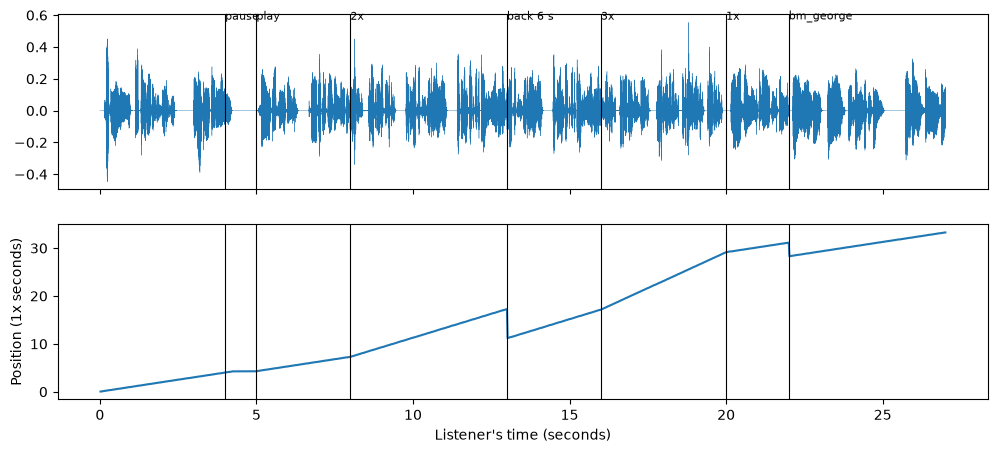

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].plot(np.arange(len(recording)) / SR, recording, lw=0.3)
axes[1].plot(times, positions)
axes[1].set_ylabel("Position (1x seconds)")
axes[1].set_xlabel("Listener's time (seconds)")
for at, label in [(4, "pause"), (5, "play"), (8, "2x"), (13, "back 6 s"), (16, "3x"), (20, "1x"), (22, "bm_george")]:
    for ax in axes:
        ax.axvline(at, color="k", lw=0.8)
    axes[0].text(at, recording.max(), label, fontsize=8, va="bottom")
plt.show()
Audio(recording, rate=SR)

The position is the clearest picture: it climbs at 1, then stops for the pause, climbs twice as steeply at 2x, drops
six seconds at the skip, and three times as steeply at 3x. Checks, from what came out and what the player announced:

In [ ]:
def rate(start, end):
    "How fast the position moved: 1x seconds of text per second of listening."
    return (np.interp(end, times, positions) - np.interp(start, times, positions)) / (end - start)


after_pause = recording[int(4 * SR) : int(5 * SR)]
silent_from = 4 + np.flatnonzero(np.abs(after_pause) > 1e-4).max(initial=0) / SR
print(f"pause pressed at 4.00 s, silent from {silent_from:.2f} s")
print([w for at, w in heard if 3.5 <= at < 5.5])
print(
    f"speed: {rate(0.5, 3.5):.2f} at 1x, {rate(4.5, 5):.2f} paused, {rate(9, 12.9):.2f} at 2x, {rate(16.5, 19.5):.2f} at 3x"
)
print(f"skip back: {rate(12.95, 13.05) * 0.1:+.2f} s, then", [w for at, w in heard if 13 <= at < 14])
assert silent_from < 4.8, "a pause should land within a word"
assert abs(rate(0.5, 3.5) - 1) < 0.05 and abs(rate(9, 12.9) - 2) < 0.1 and abs(rate(16.5, 19.5) - 3) < 0.15
print("after switching voice:", [w for at, w in heard if 22 <= at])
assert [w for at, w in heard if 22 <= at], "the new voice should carry on reading"
assert rate(4.5, 5) == 0 and -6.5 < rate(12.95, 13.05) * 0.1 < -5.5

pause pressed at 4.00 s, silent from 4.28 s
['Homer', "Dudley's"]
speed: 0.99 at 1x, 0.00 paused, 1.99 at 2x, 3.01 at 3x
skip back: -5.90 s, then ['year', 'of', 'practice', 'to', 'make', 'it', 'say', 'anything', 'at', 'all']
after switching voice: ['Neural', 'voices', 'arrived', 'in', '2016', 'They', 'sound', 'far', 'more', 'human']


## With speakers

The same player on the sound card, with buttons, and a menu of Kokoro's 28 English voices (`af` and `am` are
American, `bf` and `bm` British). This cell doesn't run under `nbdev-test`, since it makes a noise.
The current word is shown in bold as it's spoken: that's audio-reader's `willSpeakRange`. If the buttons don't respond, your editor isn't
passing widget clicks back to the kernel (JupyterLab does: `uv run jupyter lab`). The player doesn't need them, though:
`player.play()`, `player.pause()`, `player.skip(-15)` and `player.set_speed(2)` work from any cell. *Stop* closes
the speakers; run the cell again to reopen them.

In [ ]:
#| eval: false
voices = sorted(f[7:-3] for f in list_repo_files("hexgrad/Kokoro-82M") if f.startswith(("voices/a", "voices/b")))
player = Player(article)
text = widgets.HTML()


def show(a, b):
    t = player.text
    text.value = f"{escape(t[max(0, a - 120) : a])}<b>{escape(t[a:b])}</b>{escape(t[b : b + 120])}"


player.on_word = show
toggle = widgets.ToggleButton(description="Play")
back, forward = widgets.Button(description="« 15 s"), widgets.Button(description="15 s »")
stop = widgets.Button(description="Stop")
voice = widgets.Dropdown(options=voices, value=player.voice, description="Voice")
speed = widgets.Dropdown(options=[0.5, 0.75, 1, 1.25, 1.5, 2, 2.5, 3], value=1, description="Speed")
toggle.observe(lambda c: player.play() if c.new else player.pause(), "value")
back.on_click(lambda _: player.skip(-15))
forward.on_click(lambda _: player.skip(15))
stop.on_click(lambda _: stream.close())
speed.observe(lambda c: player.set_speed(c.new), "value")
voice.observe(lambda c: player.set_voice(c.new), "value")
stream = player.speakers()
display(widgets.VBox([widgets.HBox([back, toggle, forward, stop]), widgets.HBox([voice, speed]), text]))

voices/am_puck.pt: reconstructing file:   0%|          |  0.00B /  523kB            

voices/am_puck.pt: downloading bytes:           |  0.00B            

voices/bf_alice.pt: reconstructing file:   0%|          |  0.00B /  523kB            

voices/bf_alice.pt: downloading bytes:           |  0.00B            

voices/bm_daniel.pt: reconstructing file:   0%|          |  0.00B /  523kB            

voices/bm_daniel.pt: downloading bytes:           |  0.00B            

voices/bm_fable.pt: reconstructing file:   0%|          |  0.00B /  523kB            

voices/bm_fable.pt: downloading bytes:           |  0.00B            

voices/bm_lewis.pt: reconstructing file:   0%|          |  0.00B /  523kB            

voices/bm_lewis.pt: downloading bytes:           |  0.00B            

## Summary

| Control | How this player does it |
|---|---|
| Play | renders sentence by sentence, a few ahead, so the first sound waits for one sentence |
| Follow the words | announces each word, with its place in the text, as it's fed to Sonic |
| Pause | plays on to the end of the current word, then lets Sonic drain |
| Resume | carries on from the same sample |
| Seek and skip | to any word, in 1x time, so positions don't depend on speed |
| Speed | Sonic's speed, changed between one block and the next |
| Voice | not something Alex can do mid-utterance: re-renders from the start of the current sentence |

Two things are approximate. Words are announced when they're fed to Sonic, which is slightly before they're heard:
Sonic holds a few tens of milliseconds, and the sound card its own buffer. And the timeline is estimated until
sentences are rendered, so a long skip forward lands on a sentence start rather than the exact second.

## Next

- Measure, rather than assume, the time from pressing play or seek to hearing sound, and how far ahead the renderer
  stays at 3x.
- Then the phones: export Kokoro to Core ML and an Android runtime, compile Sonic for both, and check this player's
  behaviour survives.

## Things to try

- Change `lookahead` to 0 and play at 3x. When does the renderer stop keeping up?
- Announce words when they're *heard* rather than fed: Sonic's `sonicSamplesAvailable` and the stream's latency say
  how far behind the speaker is.
- Pausing waits for the end of the word. Try pausing at the end of the sentence instead, and see which feels better.